# Avance 4 — Modelos alternativos

**Bioactive AI** · Equipo 7 · Maestría en Inteligencia Artificial Aplicada (TC5035.10)

Compara familias de modelos **individuales** sobre las dos fases del proyecto, ajusta las dos
mejores y elige una. Parte del nivel de referencia del [Avance 3](03_Baseline.html) y usa la
misma partición agrupada y las mismas métricas, para que las cifras sean comparables.


## 1. Preparación

In [1]:
import os
# Un solo hilo por modelo: así la columna de tiempos significa lo mismo en todas las filas.
os.environ["OMP_NUM_THREADS"] = "1"

import platform
import warnings
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             matthews_corrcoef, precision_recall_curve, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120

# Este notebook se ejecuta desde `notebooks/` o desde la raíz del repositorio.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADOS = RAIZ / "data/processed"

In [2]:
# Versiones con las que se ejecutó. Las cifras cambian en el tercer decimal entre versiones,
# así que sin esto una salida no se puede rastrear a su entorno. Tiene que decir Python 3.12.
print(f"sistema  {platform.platform()}")
print(f"python   {platform.python_version()}")
for m in (np, pd, sklearn):
    print(f"{m.__name__:<8} {m.__version__}")

sistema  Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.41
python   3.12.15
numpy    2.5.4
pandas   3.0.6
sklearn  1.9.1


### Tres funciones cortas

Todo lo demás es scikit-learn directo. Estas tres son lo único propio del notebook:

- **`grupos_cv`**: junta andamio y esqueleto de conectividad en un solo grupo. Es lo que impide que
  dos análogos del mismo compuesto caigan en pliegues distintos. Sin esto las cifras se inflan entre
  7 y 13 puntos (medido en la fase 1: agrupar solo por andamio da
  2.2 puntos más de AUROC y 7.1 más de MCC).
- **`medir`**: MCC, AUROC y AUPRC de la clase minoritaria. El MCC se calcula con la etiqueta que
  predice el modelo, y las otras dos con su puntaje.
- **`evaluar`**: validación cruzada agrupada, tres semillas y cinco pliegues. Si recibe una rejilla,
  elige los hiperparámetros **dentro** del pliegue, con una validación interna que también agrupa.

In [3]:
SIN_ANDAMIO = "<aciclico>"   # los compuestos sin anillos no tienen andamio


def grupos_cv(andamio, esqueleto):
    """Grupo = esqueleto de conectividad, unido al andamio cuando lo hay."""
    padre = {}

    def raiz(x):
        while padre.setdefault(x, x) != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        return x

    for a, e in zip(andamio, esqueleto):
        if a != SIN_ANDAMIO:
            padre[raiz("A" + a)] = raiz("E" + e)
    return np.array([raiz("E" + e) for e in esqueleto])


def medir(y, etiqueta, puntaje):
    minoritaria = y.mean() <= 0.5          # cuál es la minoritaria cambia entre fases
    ym, pm = (y, puntaje) if minoritaria else (1 - y, -puntaje)
    return {"mcc": matthews_corrcoef(y, etiqueta),
            "auroc": roc_auc_score(y, puntaje),
            "auprc_minoritaria": average_precision_score(ym, pm)}


def evaluar(modelos, X, y, grupos, estratos=None, semillas=(0, 1, 2), pliegues=5, rejillas=None):
    """Una fila por (modelo, semilla, pliegue, estrato) y las predicciones fuera de pliegue."""
    filas = []
    fuera = {n: (np.full((len(semillas), len(y)), np.nan),
                 np.full((len(semillas), len(y)), -1)) for n in modelos}
    for s, semilla in enumerate(semillas):
        cv = StratifiedGroupKFold(pliegues, shuffle=True, random_state=semilla)
        for k, (ajuste, val) in enumerate(cv.split(X, y, grupos), 1):
            for nombre, modelo in modelos.items():
                m = clone(modelo)
                # La semilla cambia la partición y también la del modelo.
                m.set_params(**{p: semilla for p in m.get_params() if p.endswith("random_state")})
                if rejillas and nombre in rejillas:
                    m = GridSearchCV(m, rejillas[nombre], scoring="matthews_corrcoef", n_jobs=1,
                                     cv=StratifiedGroupKFold(3, shuffle=True, random_state=semilla))
                    reloj = perf_counter()
                    m.fit(X[ajuste], y[ajuste], groups=grupos[ajuste])
                else:
                    reloj = perf_counter()
                    m.fit(X[ajuste], y[ajuste])
                seg = perf_counter() - reloj
                puntaje = (m.predict_proba(X[val])[:, 1] if hasattr(m, "predict_proba")
                           else m.decision_function(X[val]))
                etiqueta = m.predict(X[val])
                fuera[nombre][0][s, val], fuera[nombre][1][s, val] = puntaje, etiqueta
                fila = dict(modelo=nombre, semilla=semilla, pliegue=k, seg=seg)
                if hasattr(m, "best_params_"):
                    fila["elegidos"] = str(m.best_params_)
                filas.append({**fila, "estrato": "todos", **medir(y[val], etiqueta, puntaje)})
                if estratos is None:
                    continue
                for e in np.unique(estratos[val]):
                    sel = estratos[val] == e
                    ys = y[val][sel]
                    if min(ys.sum(), (1 - ys).sum()) >= 20:      # estrato con 20 casos de cada clase
                        filas.append({**fila, "estrato": e,
                                      **medir(ys, etiqueta[sel], puntaje[sel])})
    return pd.DataFrame(filas), fuera


def tabla(res, estrato="todos"):
    """Media por modelo, ordenada por MCC. `desv_mcc` es dispersión entre pliegues, no error estándar."""
    d = res[res["estrato"] == estrato]
    t = d.groupby("modelo")[["mcc", "auroc", "auprc_minoritaria", "seg"]].mean()
    t.insert(1, "desv_mcc", d.groupby("modelo")["mcc"].std())
    return t.sort_values("mcc", ascending=False).round(3)

### Los datos

Salen del [notebook 02](02_Feature_Eng.html) (fase 1) y del [02b](02b_Feature_Eng_actividad.html)
(fase 2), que dejan sus matrices en `data/processed/`. Ese directorio no se versiona, así que hay que
haber ejecutado esos dos notebooks antes. Si falta un archivo, la celda lo dice.

- **Fase 1, permeabilidad:** 151 descriptores de RDKit sin transformar (el escalado se hace dentro de
  cada modelo, para que no vea el pliegue de evaluación) y la etiqueta BBB+ / BBB−.
- **La prueba reservada queda fuera.** Aquí solo se usan entrenamiento y validación.

In [4]:
for f in ("bbb_meta.parquet", "bbb_descriptores_filtrados_sin_normalizar.parquet",
          "fase2_pares.parquet", "fase2_descriptores_limpios.parquet"):
    if not (PROCESADOS / f).exists():
        raise FileNotFoundError(f"Falta data/processed/{f}. Lo genera el notebook 02 (bbb_*) "
                                "o el 02b (fase2_*); ejecútenlos primero.")

meta = pd.read_parquet(PROCESADOS / "bbb_meta.parquet")
descriptores = pd.read_parquet(PROCESADOS / "bbb_descriptores_filtrados_sin_normalizar.parquet")

uso = meta["particion"].ne("prueba").to_numpy()               # la prueba no se toca
m1 = meta[uso].reset_index(drop=True)
X1 = descriptores.to_numpy(dtype="float32")[uso]
y1 = m1["y"].astype(int).to_numpy()                           # BBB+ = 1
g1 = grupos_cv(m1["andamio"].fillna(SIN_ANDAMIO), m1["esqueleto"])
print(f"{X1.shape[0]:,} compuestos · {X1.shape[1]} descriptores · {len(np.unique(g1)):,} grupos "
      f"· {y1.mean():.1%} BBB+")

6,306 compuestos · 151 descriptores · 1,048 grupos · 65.0% BBB+


## 2. Las seis familias

Seis algoritmos **sin ensamble** con sesgos distintos: un modelo lineal (la logística, el control
interpretable), un árbol, uno basado en vecinos, uno generativo (Naive Bayes), uno de núcleo
(SVM con RBF) y una red pequeña. La rúbrica evalúa que sean variados, no que sean los seis de
mayor métrica: el árbol y Naive Bayes entran aunque queden últimos. Se descartaron LDA, por
parecerse a la logística, y el SVM lineal por SGD, porque el SVM con RBF ya cubre esa familia.

In [5]:
SEIS = ("logistica", "arbol", "knn", "bayes", "svm_rbf", "mlp")
PRINCIPAL = "mcc"          # la métrica que ordena la tabla; vale 0 para un modelo trivial

# Los que necesitan escala la llevan dentro, para ajustarla solo con el pliegue de entrenamiento.
modelos = {
    "logistica": make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=3000)),
    "arbol":     DecisionTreeClassifier(min_samples_leaf=5),
    "knn":       make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=15)),
    "bayes":     make_pipeline(MinMaxScaler(), GaussianNB()),
    "svm_rbf":   make_pipeline(MinMaxScaler(), SVC()),
    "mlp":       make_pipeline(MinMaxScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=600)),
}
assert tuple(modelos) == SEIS

## 3. Comparativa

Las seis familias con partición agrupada por andamio y esqueleto, tres semillas y cinco pliegues,
como en el Avance 3. Los tiempos son de reloj de pared, así que para que la columna
signifique lo mismo en todas las filas hay que correr con el mismo paralelismo.

In [6]:
res1, fdp1 = evaluar(modelos, X1, y1, g1)
tabla1 = tabla(res1)
tabla1

,mcc,desv_mcc,auroc,auprc_minoritaria,seg
modelo,,,,,
svm_rbf,0.703,0.077,0.919,0.884,0.540
logistica,0.688,0.065,0.913,0.872,0.028
mlp,0.674,0.070,0.913,0.865,5.682
knn,0.669,0.081,0.914,0.863,0.004
arbol,0.568,0.081,0.836,0.706,0.247
bayes,0.566,0.094,0.857,0.801,0.007


#### Qué dice la tabla de la fase 1

**Cuatro modelos quedan arriba y no se pueden distinguir entre sí.** El SVM con RBF encabeza con 0.703 de MCC, seguido de la logística (0.688), la red (0.674) y el kNN (0.669). Entre el primero y el cuarto hay unas treinta milésimas, y el resultado se mueve más que eso de una evaluación a otra (de 0.065 a 0.094), así que no hay un ganador claro. El árbol (0.568) y Naive Bayes (0.566) sí se quedan atrás, por una décima.

El AUROC cuenta lo mismo: los cuatro de arriba están entre 0.913 y 0.919. Por eso la regla de «los dos mejores», que se fijó antes de correr, separa al kNN de la logística por solo una milésima; la §6 vuelve sobre esto.

**El tiempo, en cambio, sí cambia mucho.** La logística tarda 0.028 s por evaluación y el kNN 0.004 s, contra 0.54 s del SVM y 5.7 s de la red: una diferencia enorme de tiempo por una diferencia de desempeño que no se distingue.


In [7]:
# Los dos ensambles del Avance 3, como referencia y fuera del conteo de seis.
referencia = {
    "bosque (A3)": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=1),
    "boosting (A3)": HistGradientBoostingClassifier(),
}
ref1, _ = evaluar(referencia, X1, y1, g1)
tabla(ref1)

,mcc,desv_mcc,auroc,auprc_minoritaria,seg
modelo,,,,,
boosting (A3),0.702,0.063,0.930,0.884,1.133
bosque (A3),0.698,0.072,0.933,0.895,3.741


### 3.1 Fase 2 · Actividad en el sistema nervioso

> **Cómo se lee esta sección.** A raíz de unas dudas sobre las fuentes de los datos y la naturaleza bioquímica de las mediciones llegamos a una ambigüedad sobre qué debía predecir la fase 2, y la resolvimos con la Dra. Mariana. Esta sección de clasificación la agregamos para dar continuidad al ejercicio del baseline, pero ya no es el ejercicio principal de la fase 2: se hace solo como **referencia y exploración** de ese planteamiento. La comparativa de la regresión está en el notebook [04b](04b_Regresion_actividad.html).

La fase 2 tiene 54,369 pares y la unidad es el par compuesto-diana. Se corren los seis modelos con el mismo protocolo de la fase 1, no solo los que ganaron allá: la tarea es otra (más filas y la diana como entrada) y un modelo que gana en la fase 1 puede no ganar aquí.

El SVM con RBF es el más lento y el que fija cuánto tarda esta sección: unos 155 s por evaluación, cerca de 39 minutos en las quince, y la corrida entera del notebook pasa de una hora. La columna `seg` de la tabla es la medición real.


In [8]:
pares = pd.read_parquet(PROCESADOS / "fase2_pares.parquet")
desc2 = pd.read_parquet(PROCESADOS / "fase2_descriptores_limpios.parquet")
d2 = (pares[pares["activo_10um"].notna() & pares["particion"].ne("prueba")]
      .merge(desc2, on="smiles").reset_index(drop=True))
cols = [c for c in desc2.columns if c != "smiles"]
# La diana entra como columnas 0/1: sin ella el modelo no sabe contra qué se mide.
X2 = np.hstack([d2[cols].to_numpy("float32"), pd.get_dummies(d2["target_gene"]).to_numpy("float32")])
y2 = d2["activo_10um"].astype(int).to_numpy()
g2 = d2["grupo_cv"].to_numpy()
procedencia = d2["estrato"].to_numpy()              # solo_chembl, solo_npass, mixto

res2, _ = evaluar(modelos, X2, y2, g2, estratos=procedencia)

tabla2 = tabla(res2)
display(tabla2)

# ¿Se mantiene el orden de la fase 1? Posición de cada modelo según AUROC y según MCC.
pd.DataFrame({
    "AUROC fase 1": tabla1["auroc"].rank(ascending=False),
    "AUROC fase 2": tabla2["auroc"].rank(ascending=False),
    "MCC fase 1": tabla1["mcc"].rank(ascending=False),
    "MCC fase 2": tabla2["mcc"].rank(ascending=False),
}).astype(int).sort_values("AUROC fase 1")

,mcc,desv_mcc,auroc,auprc_minoritaria,seg
modelo,,,,,
mlp,0.499,0.014,0.838,0.690,45.467
knn,0.496,0.014,0.846,0.692,0.046
svm_rbf,0.441,0.019,0.831,0.678,155.749
logistica,0.387,0.019,0.795,0.612,0.850
arbol,0.368,0.016,0.728,0.499,4.539
bayes,0.247,0.030,0.629,0.399,0.094


,AUROC fase 1,AUROC fase 2,MCC fase 1,MCC fase 2
modelo,,,,
svm_rbf,1,3,1,3
knn,2,1,4,2
mlp,3,2,3,1
logistica,3,4,2,4
bayes,5,6,6,6
arbol,6,5,5,5


#### Qué dice la fase 2, y por qué el orden cambia

**El orden cambia, y esta vez sí se nota.** En la fase 1 encabezaba el SVM, pero había cuatro modelos empatados arriba. Aquí encabezan la red (0.499 de MCC) y el kNN (0.496), y el SVM baja al tercer lugar con 0.441. La logística, que era segunda, cae al cuarto con 0.387; el árbol queda en 0.368 y Naive Bayes, otra vez último, en 0.247. El AUROC cuenta lo mismo: 0.846 del kNN y 0.838 de la red, contra 0.831 del SVM y 0.795 de la logística.

**Por qué cambia.** Son los mismos cuatro modelos arriba, pero ordenados distinto, por dos cosas. La primera es que en la fase 1 el orden entre ellos era ruido: el resultado se movía hasta 0.09 de MCC entre evaluaciones, más que la diferencia que los separaba. En la fase 2 se mueve mucho menos (de 0.014 a 0.030), así que las diferencias reales se ven: el SVM queda seis centésimas por debajo de la red y el kNN, unas tres veces lo que oscila. La segunda es la tarea: hay nueve veces más filas (54,369 pares contra 6,306 compuestos) y la diana entra como entrada, y a los modelos que se adaptan a los datos (la red y el kNN) les sirve más tener tantos ejemplos que a la logística, que es la que más cae (de 0.688 a 0.387). Esa segunda explicación es razonable, pero este cuaderno no la prueba.

Las cifras absolutas son más bajas que en la fase 1 (0.50 contra 0.70 de MCC) y no se pueden comparar entre sí, porque son tareas distintas: otra unidad, otro desbalance y la diana como entrada. Lo que sí se compara es el orden, y que cambie es la razón de correr los seis modelos en las dos fases: elegir el modelo de una mirando la otra habría sido un error.

**Con los productos naturales, un promedio no alcanza.** Un solo número no dice cómo le va al modelo con los compuestos que solo tiene NPASS, que son los que el proyecto quiere priorizar. Ese desglose, para la regresión, está en el [04b](04b_Regresion_actividad.html).


## 4. Ajuste fino de las dos mejores

La búsqueda va **dentro** del pliegue y su validación interna también agrupa. Hacerlo con una
partición aleatoria dejaría la evaluación externa intacta y elegiría la rejilla sobre una
medición inflada entre 7 y 13 puntos, que es una fuga que no aparece en ninguna métrica.
Las dos mejores son **los dos modelos de mayor AUROC en la comparación de la fase 1**, regla fijada antes
de correr. Se afinan en la fase 1; en la fase 2 se compara a los seis sin afinar. La elección de los dos
usa la misma comparación que luego se reporta, así que tiene un sesgo pequeño que se declara; el ajuste
en sí es anidado y sus cifras son honestas.

In [9]:
# Regla fijada antes de correr: los dos de mayor AUROC en la comparación de la fase 1.
DOS = list(tabla1.sort_values("auroc", ascending=False).index[:2])
print("los dos de mayor AUROC:", DOS)

# Rejillas de las seis; solo se usan las de los dos elegidos. Búsqueda exhaustiva en todas.
# Los nombres son los que make_pipeline le da a cada paso (minúsculas del nombre de la clase).
REJILLAS = {
    "logistica": {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    "arbol":     {"max_depth": [3, 6, 10, None], "min_samples_leaf": [1, 5, 20]},
    "knn":       {"kneighborsclassifier__n_neighbors": [5, 15, 30, 50],
                  "kneighborsclassifier__weights": ["uniform", "distance"]},
    "bayes":     {"gaussiannb__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]},
    "svm_rbf":   {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", "auto"]},
    "mlp":       {"mlpclassifier__hidden_layer_sizes": [(32,), (64,), (128,)],
                  "mlpclassifier__alpha": [1e-5, 1e-4, 1e-3, 1e-2]},
}

afinados = {f"{n} afinado": modelos[n] for n in DOS}
rejillas = {f"{n} afinado": REJILLAS[n] for n in DOS}
res_af, fdp_af = evaluar(afinados, X1, y1, g1, rejillas=rejillas)
tabla(res_af)

los dos de mayor AUROC: ['svm_rbf', 'knn']


,mcc,desv_mcc,auroc,auprc_minoritaria,seg
modelo,,,,,
svm_rbf afinado,0.699,0.073,0.916,0.876,10.790
knn afinado,0.675,0.079,0.916,0.874,1.374


#### Qué compró el ajuste fino

**Prácticamente nada, y conviene decirlo así.**

| Modelo | MCC | AUROC | AUPRC min. | seg |
|:--|--:|--:|--:|--:|
| `svm_rbf` sin afinar | 0.703 | 0.919 | 0.884 | 0.540 |
| `svm_rbf` afinado | 0.699 | 0.916 | 0.876 | 10.79 |
| `knn` sin afinar | 0.669 | 0.914 | 0.863 | 0.004 |
| `knn` afinado | 0.675 | 0.916 | 0.874 | 1.374 |

El SVM empeora 0.004 de MCC al afinarse y el kNN mejora 0.006. Como el resultado se mueve cerca de 0.08 de una evaluación a otra, ninguno de los dos cambios es una mejora real. Lo que sí cambió es el costo: el SVM pasa de 0.54 s a 10.8 s por evaluación (unas veinte veces más) y el kNN de 0.004 s a 1.4 s.

Hay dos razones. Una es que los modelos ya llegaban con hiperparámetros razonables, así que la rejilla busca sobre una meseta. La otra es que la búsqueda interna optimiza MCC mientras que los dos mejores se eligieron por AUROC: son criterios distintos, y unificarlos queda para el Avance 5.


### 4.1 Qué eligió la búsqueda en cada pliegue

Una rejilla que cambia de pliegue a pliegue no es un óptimo: es una elección que depende de
la partición. Es la diferencia entre un ajuste fino y una corrida afortunada.

In [10]:
print(res_af[["modelo", "semilla", "pliegue", PRINCIPAL, "elegidos"]]
      .to_string(index=False))

         modelo  semilla  pliegue      mcc                                                                               elegidos
svm_rbf afinado        0        1 0.765130                                                   {'svc__C': 1, 'svc__gamma': 'scale'}
    knn afinado        0        1 0.738517 {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'distance'}
svm_rbf afinado        0        2 0.610391                                                   {'svc__C': 1, 'svc__gamma': 'scale'}
    knn afinado        0        2 0.598642 {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'distance'}
svm_rbf afinado        0        3 0.690033                                                  {'svc__C': 100, 'svc__gamma': 'auto'}
    knn afinado        0        3 0.658531 {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'distance'}
svm_rbf afinado        0        4 0.692743                                                

#### Si lo que eligió fue estable

**Los dos modelos se comportan al revés, y eso explica por qué el ajuste no ayudó.**

| | Lo que eligió en los quince pliegues |
|:--|:--|
| `svm_rbf`, `C` | 1 (siete veces), 10 (cuatro), 100 (dos), 0.1 (dos) |
| `svm_rbf`, `gamma` | `scale` (once), `auto` (cuatro) |
| `knn`, `n_neighbors` | 15 (trece veces), 30 (dos) |
| `knn`, `weights` | `distance` (catorce), `uniform` (una) |

El `C` del SVM recorre toda la rejilla y toca los dos extremos (100 en dos pliegues y 0.1 en otros dos). No es que el mejor valor esté fuera de la rejilla: es que **no hay un valor estable**, y el que gana cambia según cómo caiga la partición. Ampliar la rejilla solo daría más valores entre los que oscilar. Por eso el ajuste no mejoró al SVM: estaba ajustando ruido de la partición.

El kNN es lo contrario. Eligió 15 vecinos en trece de los quince pliegues, que es el valor con el que ya venía, y ninguno tocó los extremos (5 y 50). Su ajuste volvió a elegir lo que ya tenía, lo que concuerda con que casi no cambie.


In [11]:
# Registro de la comparativa en experimentos/: una corrida por fase, porque cada
# decisión de docs/decisiones.md pertenece a una sola fase.
import sys
sys.path.insert(0, str(RAIZ))          # así lo hace el notebook 03
from src.tracking import Corrida

with Corrida("comparativa-6-modelos-fase-1", decision="1.5",
             params={"modelos": list(modelos), "pliegues": 5, "metrica_principal": PRINCIPAL,
                     "dos_mejores": DOS, "regla_dos_mejores": "mayor AUROC en la fase 1",
                     "rejillas": repr(rejillas)},
            semillas=[0, 1, 2],
            datos=[PROCESADOS / "bbb_descriptores_filtrados_sin_normalizar.parquet", PROCESADOS / "bbb_meta.parquet"] )  as c1, \
     Corrida("comparativa-6-modelos-fase-2", decision="2.3",
             params={"modelos": list(modelos), "pliegues": 5, "estratos": "procedencia"},
             semillas=[0, 1, 2],
             datos=[PROCESADOS / "fase2_pares.parquet", PROCESADOS / "fase2_descriptores_limpios.parquet"]) as c2:
    c1.metricas({"seis": tabla1.to_dict(orient="index"),
                 "referencia_A3": tabla(ref1).to_dict(orient="index"), 
                 "ajuste_fino": tabla(res_af).to_dict(orient="index")})
    c2.metricas({"seis": tabla2.to_dict(orient="index")})

print(c1.carpeta.name)
print(c2.carpeta.name)

2026-10-25-antonio-1.5-comparativa-6-modelos-fase-1
2026-10-25-antonio-2.3-comparativa-6-modelos-fase-2


## 5. Gráficos del mejor individual

Sobre predicciones **fuera de pliegue**, no de un modelo reajustado sobre todo el conjunto:
un gráfico hecho sobre datos que el modelo vio describe su memoria, no su desempeño.

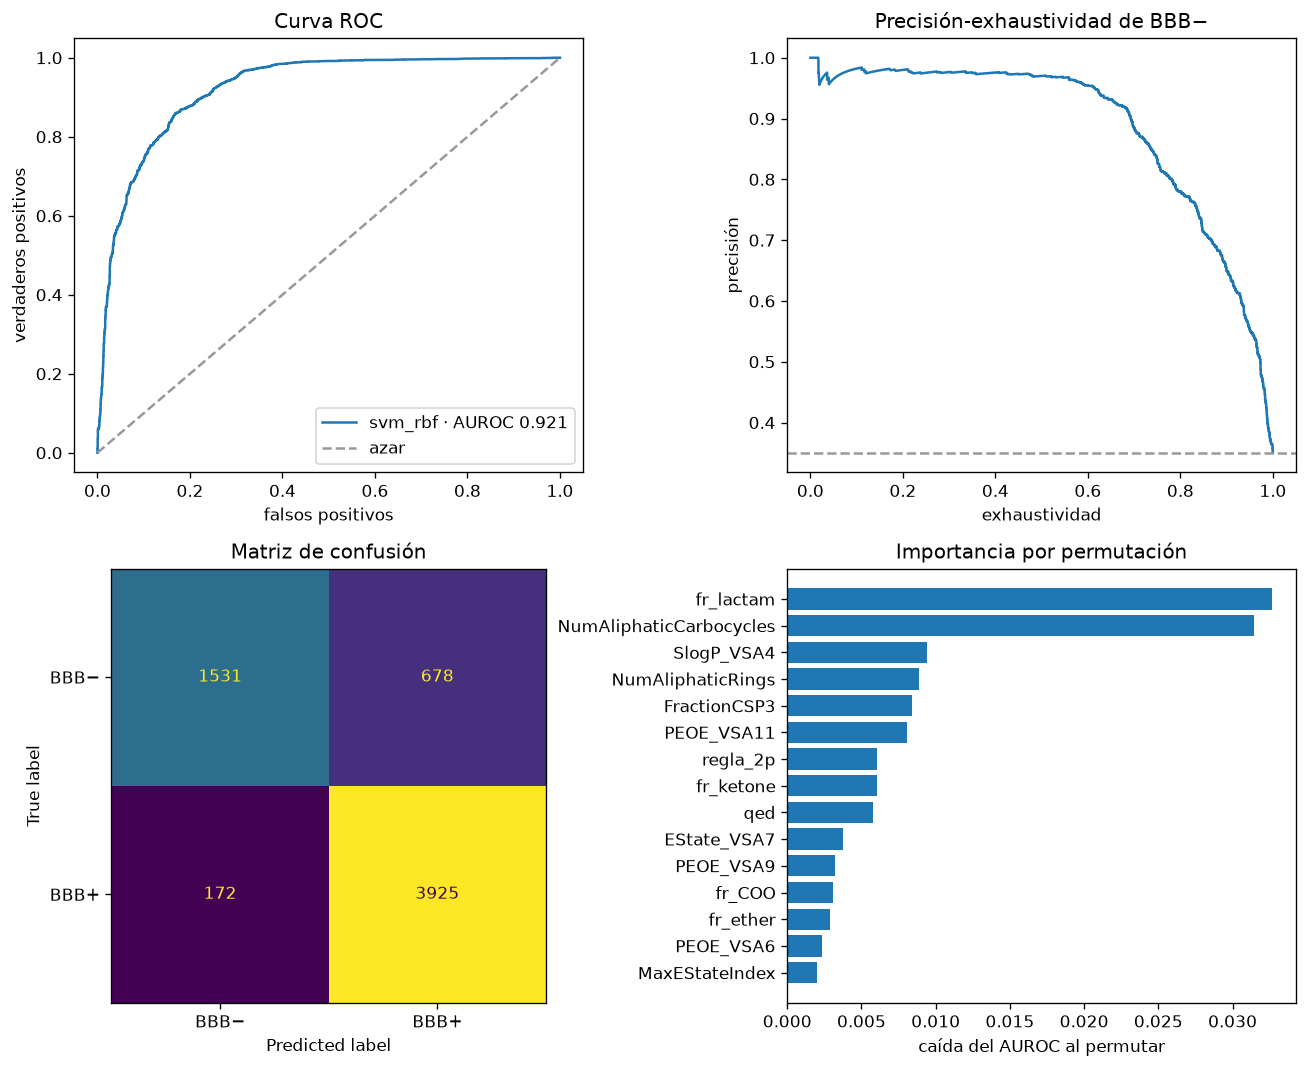

In [12]:
MEJOR = tabla1.index[0]
puntaje, etiqueta = fdp1[MEJOR]
p, e = puntaje[0], etiqueta[0].astype(int)              # semilla 0

fig, ax = plt.subplots(2, 2, figsize=(11, 9))

fpr, tpr, _ = roc_curve(y1, p)
ax[0, 0].plot(fpr, tpr, label=f"{MEJOR} · AUROC {roc_auc_score(y1, p):.3f}")
ax[0, 0].plot([0, 1], [0, 1], "--", color="0.6", label="azar")
ax[0, 0].set(xlabel="falsos positivos", ylabel="verdaderos positivos", title="Curva ROC")
ax[0, 0].legend()

prec, rec, _ = precision_recall_curve(1 - y1, -p)       # la minoritaria es BBB−
ax[0, 1].plot(rec, prec)
ax[0, 1].axhline((1 - y1).mean(), ls="--", color="0.6")
ax[0, 1].set(xlabel="exhaustividad", ylabel="precisión", title="Precisión-exhaustividad de BBB−")

ConfusionMatrixDisplay.from_predictions(y1, e, display_labels=["BBB−", "BBB+"], ax=ax[1, 0],
                                        colorbar=False)
ax[1, 0].set_title("Matriz de confusión")

# Importancia por permutación en un pliegue que el modelo no vio.
ajuste, val = next(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X1, y1, g1))
mod = clone(modelos[MEJOR]).fit(X1[ajuste], y1[ajuste])
imp = permutation_importance(mod, X1[val], y1[val], scoring="roc_auc", n_repeats=5, random_state=0)
top = pd.Series(imp.importances_mean, index=descriptores.columns).nlargest(15).iloc[::-1]
ax[1, 1].barh(top.index, top.values)
ax[1, 1].set(xlabel="caída del AUROC al permutar", title="Importancia por permutación")

fig.tight_layout()

## 6. El modelo individual final

Si los intervalos se solapan y ninguna familia se distingue, decirlo es el resultado.


El modelo individual final es el **SVM con núcleo RBF afinado**, y no solo porque gane.

**Lo que dicen las métricas.** Entre los dos afinados, el SVM saca 0.699 de MCC y el kNN 0.675, con AUROC y AUPRC prácticamente iguales (0.916 los dos, y 0.876 contra 0.874). La ventaja de 0.024 es menor que lo que se mueve el resultado entre evaluaciones, así que no hay una diferencia clara: el SVM gana por consistencia, no por distinguirse.

**Lo que las métricas no dicen, y pesa igual.**

- **El ajuste no aporta y sí cuesta.** El SVM sin afinar da casi lo mismo y es unas veinte veces más rápido.
- **La logística se quedó fuera por muy poco.** La regla de los dos mejores, que se fijó antes de correr, la dejó fuera por 0.001 de AUROC (0.913 contra 0.914 del kNN), pero su MCC es mejor (0.688 contra 0.669) y tarda 0.028 s. No cambiamos la regla después de ver los números; el resultado es que el criterio de selección y la métrica principal no coinciden, y eso se arregla en el Avance 5.
- **Interpretabilidad.** Como buscamos que el modelo explique sus decisiones, queremos implementar SHAP y otros métodos de atribución. Un SVM con núcleo RBF no tiene coeficientes que se puedan leer, así que hay que atribuirle por permutación o con SHAP. La logística sí los tiene y pierde solo 0.011 de MCC frente al SVM afinado. Cuando tengamos la explicabilidad construida hay que volver a mirar esta compensación.


# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude Code [Agente de programación]. https://claude.com/claude-code | Andamiaje del avance, escrito antes de ver cualquier resultado: el arnés que cronometra el ajuste y arma la tabla comparativa, el catálogo de familias sin ensamble, la búsqueda de hiperparámetros con validación interna agrupada, los gráficos, el esqueleto de este cuaderno, la plantilla y el verificador de esta declaración, y las métricas de regresión con censura (`src/evaluation/regresion.py`) | Secciones 1 a 3 y 5 (el código de apoyo vive en `src/`) y el esqueleto de las demás. El plan reserva al equipo, sin IA, cuáles seis familias, la métrica principal, las rejillas, las lecturas, el argumento del modelo final y la interpretación de los gráficos | **Lo que el equipo corrigió o descartó:** la validación interna de la calibración del SVM no agrupaba (revisión del #118, 23 de octubre); el kernel del cuaderno solo existía en una máquina y se pasó a `python3`, y la estimación de 15 minutos del SVM se sustituyó por la medida de 154.5 s por evaluación (revisión del 24 de octubre); se descartó la propuesta de separar la fase 2 de este avance. **Lo que se verificó:** las lecturas contra la corrida registrada en Docker sobre el cuaderno congelado, cuyas cifras coinciden; las pruebas automáticas de `src/` y del CI |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Ingrid Pamela Ruiz Puga | Planteó a la patrocinadora las dudas de la fase 2 y registró su respuesta en la bitácora, de donde sale que la variable objetivo sea la potencia y que esta tabla de clasificación sea el piso; midió, con apoyo de Claude Code, los filtros de datos que alimentan este avance (contexto del ensayo, tipo de ensayo del IC50, filas sin diana de la lista); escribió las métricas de regresión con censura y el baseline de regresión con el modelo de Tobit; revisó los PRs de este avance y ordenó su fusión |
| Artemio Santiago Padilla Robles | |
| José Antonio Vázquez Martínez | |

### Decisiones principales

**Decisión 1: seis modelos individuales, sin ensambles.**

- Justificación: la rúbrica de este avance los pide así; los ensambles se trabajan en el Avance 5.
- Alternativa descartada y motivo: incluir ensambles en esta tabla; se dejan para el siguiente avance.

**Decisión 2: en la fase 2 la variable objetivo es la potencia y esta tabla de clasificación es solo una referencia.**

- Justificación: el corte de 10 µM no es estimable sin una columna de desenlace y no significa lo mismo en cada diana (deja a `LRRK2` en 98.1% de activos y a `NFE2L2` en 50.7%), y clasificar tira el orden dentro de cada clase.
- Alternativa descartada y motivo: clasificar con un corte como modelo principal de la fase 2; se conserva solo como referencia de la regresión.

**Decisión 3: el modelo individual final se elige sobre la fase 1 y es el SVM con núcleo RBF.**

- Justificación: entre los dos afinados la diferencia de MCC (0.024) es menor que la dispersión entre evaluaciones, así que gana por consistencia y no por distinguirse; el afinado no mejoró nada, porque el `C` del SVM no tiene un óptimo estable.
- Alternativa descartada y motivo: la regresión logística, que queda fuera de los dos mejores por 0.001 de AUROC pese a tener mejor MCC y coeficientes legibles; la regla de selección se fijó antes de correr y no se cambió después de ver los números.

### Responsabilidad

Las salidas de las herramientas se usaron como insumo de trabajo y fueron revisadas,
verificadas, editadas y adaptadas por el equipo. El equipo asume la responsabilidad
por la exactitud, la integridad y el contenido final del avance.
